# 04 - National & Sector Consumption Trends

Headline volume story: how much coal the U.S. burned and which end-use sectors grew or shrank. Uses U.S. Total rows + the clean non-overlapping breakdown (98 + 8 + 9 + 10). **Note:** the data values are in *short tons* (U.S. Total 2020 electric-power coal = 435.8M short tons, matching real-world U.S. coal use); shown here in millions of short tons. 2025 is preliminary.

In [1]:
import sys, os
ROOT = os.getcwd() if os.path.exists(os.path.join(os.getcwd(), "src")) else os.path.dirname(os.getcwd())
sys.path.insert(0, ROOT)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
DATA = os.path.join(ROOT, "data", "eia_coal_consumption_quality_2020_2025.csv")
CHARTS = os.path.join(ROOT, "charts")
os.makedirs(CHARTS, exist_ok=True)
print("ROOT:", ROOT)


ROOT: C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26


In [2]:
def savefig(name):
    p = os.path.join(CHARTS, name)
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print('saved', p)
    plt.show()


In [3]:
from src.data import load_coal_data, CLEAN_SECTOR_BREAKDOWN, SECTOR_LEAVES
from src.taxonomy import add_location_level, filter_location, total_coal_use, SECTOR_DESCRIPTIONS
from src.clean import clean
df = add_location_level(clean(load_coal_data(DATA)))
us = filter_location(df, 'national')

In [4]:
# National total coal use (clean breakdown)
total = total_coal_use(df, 'national')
total_mt = total / 1e6
yoy = (total.pct_change() * 100).round(1)
summary = pd.DataFrame({'million_short_tons': total_mt.round(1), 'yoy_pct': yoy})
summary.loc[2025, 'note'] = 'preliminary'
summary

,million_short_tons,yoy_pct,note
period,,,
2020,476.7,NaN,NaN
2021,545.7,14.5,NaN
2022,515.5,-5.5,NaN
2023,425.9,-17.4,NaN
2024,410.9,-3.5,NaN
2025,450.8,9.7,preliminary


saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\04_national_consumption_trend.png


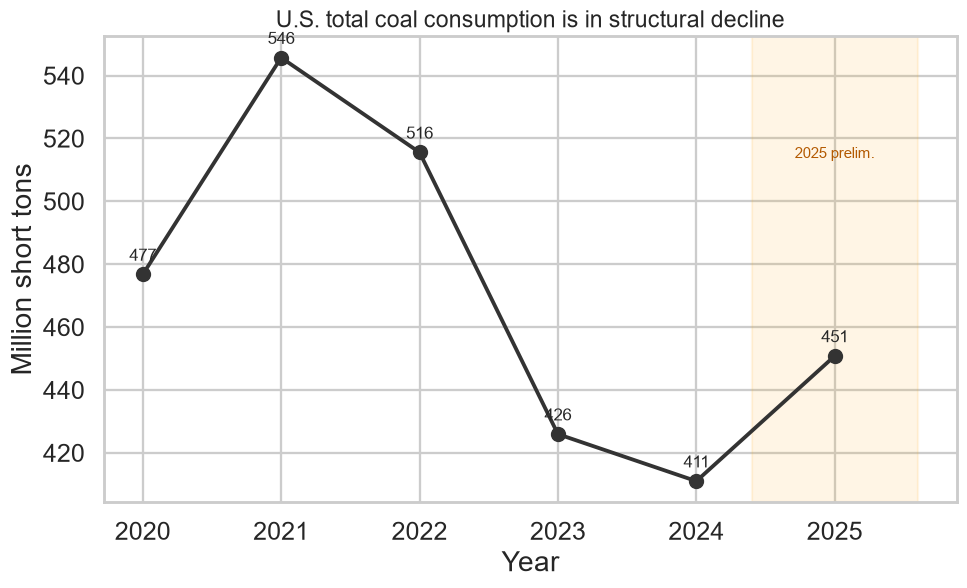

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(total_mt.index, total_mt.values, marker='o', lw=2.5, color='#333333')
for x, y in zip(total_mt.index, total_mt.values):
    ax.annotate(f'{y:.0f}', (x, y), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=11)
ax.axvspan(2024.4, 2025.6, color='orange', alpha=0.10)
ax.text(2025, ax.get_ylim()[1]*0.93, '2025 prelim.', color='#b35900', fontsize=10, ha='center')
ax.set_title('U.S. total coal consumption is in structural decline', fontsize=15)
ax.set_xlabel('Year'); ax.set_ylabel('Million short tons')
ax.set_xticks(list(total_mt.index))
savefig('04_national_consumption_trend.png')

In [6]:
# Sector breakdown (clean, non-overlapping)
sect = us[us['sector'].isin(CLEAN_SECTOR_BREAKDOWN)].copy()
piv = (sect.pivot_table(index='period', columns='sector', values='consumption', aggfunc='sum') / 1e6)
piv = piv[[98, 10, 9, 8]]
piv.columns = [SECTOR_DESCRIPTIONS[c] for c in piv.columns]
piv.round(1)

,Electric Power,Other Industrial,Coke Plants,Commercial and Institutional
period,,,,
2020,435.8,25.7,14.4,0.8
2021,501.4,25.8,17.6,0.8
2022,472.8,25.9,16.0,0.8
2023,387.2,22.2,15.8,0.7
2024,373.3,21.5,15.5,0.6
2025,415.4,20.1,14.6,0.7


saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\04_sector_stacked_area.png


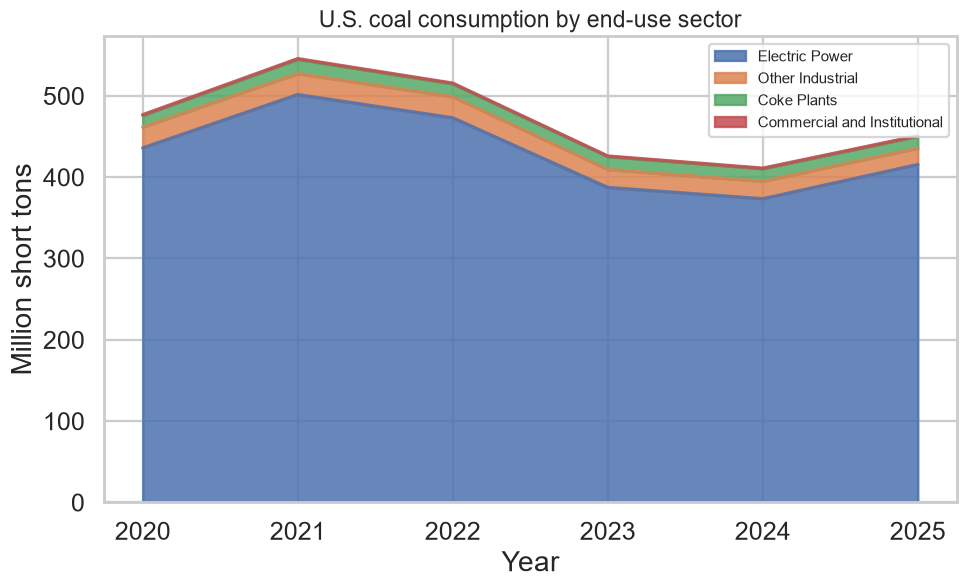

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))
piv.plot.area(ax=ax, alpha=0.85, color=['#4c72b0', '#dd8452', '#55a868', '#c44e52'])
ax.set_title('U.S. coal consumption by end-use sector', fontsize=15)
ax.set_xlabel('Year'); ax.set_ylabel('Million short tons')
ax.legend(title='', loc='upper right', fontsize=10)
savefig('04_sector_stacked_area.png')

In [8]:
# YoY % change by sector
yoy_sect = (piv.pct_change() * 100).round(1)
yoy_sect

,Electric Power,Other Industrial,Coke Plants,Commercial and Institutional
period,,,,
2020,NaN,NaN,NaN,NaN
2021,15.1,0.7,22.0,2.2
2022,-5.7,0.2,-9.0,-1.3
2023,-18.1,-14.4,-1.0,-16.5
2024,-3.6,-2.8,-2.2,-5.2
2025,11.3,-6.6,-5.9,4.3


saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\04_sector_yoy_bar.png


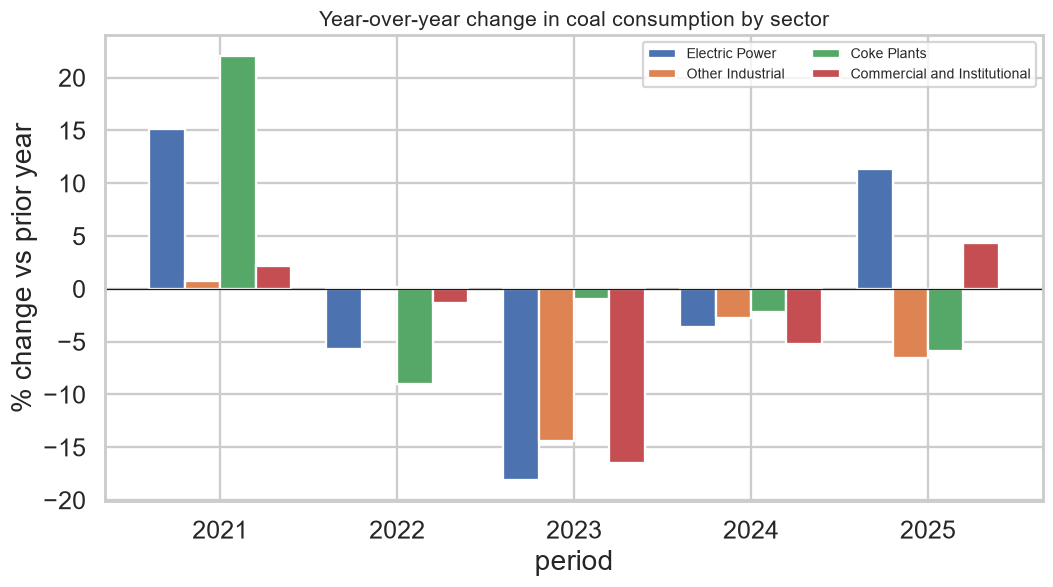

In [9]:
fig, ax = plt.subplots(figsize=(11, 5.5))
yoy_sect.dropna().plot.bar(ax=ax, width=0.8)
ax.set_title('Year-over-year change in coal consumption by sector', fontsize=14)
ax.set_ylabel('% change vs prior year'); ax.axhline(0, color='k', lw=0.8)
ax.legend(title='', fontsize=9, ncol=2)
plt.xticks(rotation=0)
savefig('04_sector_yoy_bar.png')

In [10]:
# Within electric power: Electric Utility (1) vs IPP Non-CHP (2) vs IPP CHP (3)
ep = us[us['sector'].isin([1, 2, 3])].copy()
epp = (ep.pivot_table(index='period', columns='sector', values='consumption', aggfunc='sum') / 1e6)
epp = epp[[1, 2, 3]]
epp.columns = [SECTOR_DESCRIPTIONS[c] for c in epp.columns]
epp.round(1)

,Electric Utility,IPP Non-CHP,IPP CHP
period,,,
2020,327.0,101.8,7.0
2021,374.8,119.8,6.7
2022,351.6,114.8,6.5
2023,292.6,89.3,5.3
2024,286.3,82.6,4.4
2025,319.1,93.7,2.7


saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\04_electric_power_leaves.png


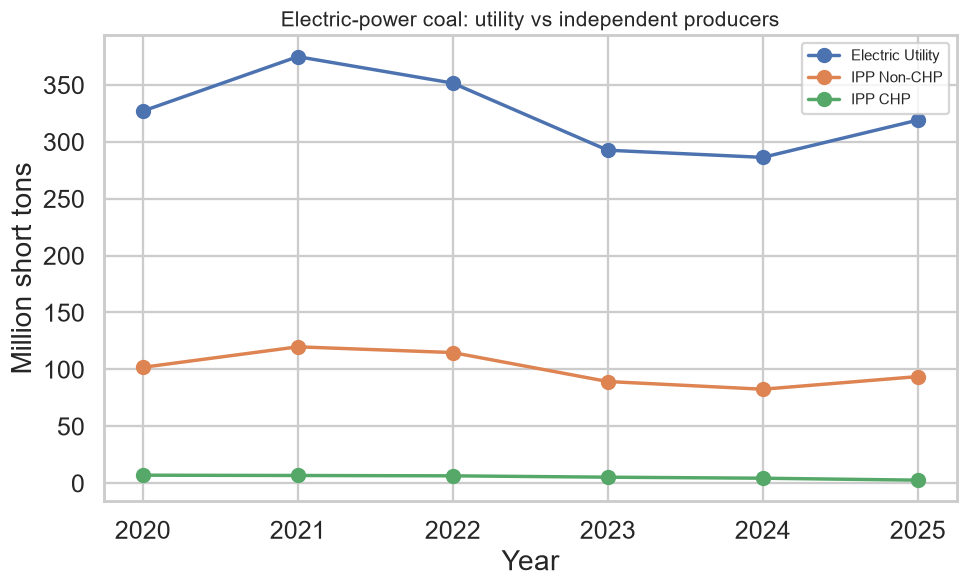

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for c in epp.columns:
    ax.plot(epp.index, epp[c], marker='o', label=c)
ax.set_title('Electric-power coal: utility vs independent producers', fontsize=14)
ax.set_xlabel('Year'); ax.set_ylabel('Million short tons'); ax.legend(fontsize=10)
savefig('04_electric_power_leaves.png')

In [12]:
# Guard: national total equals sum of clean sectors
manual = us[us['sector'].isin(CLEAN_SECTOR_BREAKDOWN)].groupby('period')['consumption'].sum(min_count=1)
assert (manual.round(0) == total.round(0)).all(), 'clean breakdown does not match total'
print('Clean breakdown reconciles to national total - no double counting.')

Clean breakdown reconciles to national total - no double counting.


**Takeaways**
- Total U.S. coal consumption fell sharply from 2020 to a trough, with electric power (sector 98) the dominant and declining driver.
- Coke Plants (met coal for steel) and Other Industrial are far smaller; their trajectories differ from power coal - key for the industry split.
- 2025 is preliminary (orange band); treat its level with caution but the direction is informative.